In [2]:
import uproot, awkward as ak, numpy as np, matplotlib.pyplot as plt
print(uproot.__version__, ak.__version__)

5.7.7 2.14.0


In [3]:
import uproot
file = uproot.open("/afs/cern.ch/work/f/frresend/MG5_aMC_v3_5_17/test_dy/Events/run_02/tag_1_delphes_events.root")
#print(file.keys())

In [4]:
delphes_events = file['Delphes;1']
#print(delphes_events.keys())
muon_events = delphes_events['Muon']
array_muon_events = muon_events.array()
print(array_muon_events)
#print(muon_events)
#print(delphes_events['Muon_size'])
muon_eta = muon_events['Muon.Eta']
muon_phi = muon_events['Muon.Phi']
muon_charge = muon_events['Muon.Charge']
muon_pt = muon_events['Muon.PT']
print(muon_eta)
#print(muon_events.keys())
#print(muon_events['Muon_Size'])
muon_events_eta_array = muon_eta.array()
muon_events_pt_array = muon_pt.array()
muon_events_charge_array = muon_charge.array()
muon_events_phi_array = muon_phi.array()
print(muon_events_eta_array, muon_events_pt_array, muon_events_charge_array, muon_events_phi_array)
values, counts = np.unique(muon_events, return_counts=True)
#plt.stairs(counts, bins)
print(values, counts)
print(counts[2]/(counts[0]+counts[1]+counts[2]))
print(counts[2]/(counts.sum()))

[2, 2, 1, 2, 2, 2, 2, 2, 2, 1, 2, 1, 1, ..., 2, 2, 2, 2, 2, 1, 2, 2, 2, 1, 1, 2]
<TBranchElement 'Muon.Eta' at 0x7f535769e690>
[[1.4, -1.06], [-0.651, -2.48], [-1.49], ..., [1.4], [1.57], [0.694, 2.23]] [[29.2, 27.9], [33, 25.2], [35.4], [...], ..., [15.8], [41.3], [36.9, 32.2]] [[-1, 1], [-1, 1], [1], [1, -1], [-1, 1], ..., [1, -1], [1], [-1], [-1, 1]] [[-0.0189, 3.11], [1.46, -0.748], [-1.85], ..., [1.17], [2.94], [-0.846, 2.34]]
[0 1 2] [ 289 2892 6819]
0.6819
0.6819


In [5]:
mask = (ak.num(muon_events_pt_array) == 2) & (ak.sum(muon_events_charge_array, axis=1) == 0)

In [6]:
muons = muon_events.arrays(["Muon.PT", "Muon.Eta", "Muon.Phi", "Muon.Charge"])
muons_sel = muons[mask]

muons_sel["Muon.PT"]   # pt of the selected events

<Array [[29.2, 27.9], [33, ...], ..., [36.9, 32.2]] type='6819 * var * float32'>

In [7]:
print(muons_sel["Muon.PT"])

[[29.2, 27.9], [33, 25.2], [43.3, 43], ..., [...], [83.6, 22.2], [36.9, 32.2]]


In [8]:
ak.sum(mask)

np.int64(6819)

In [9]:
def to_cartesian(pt, phi, eta, m):
    px = pt*np.cos(phi)
    py = pt*np.sin(phi)
    pz = pt*np.sinh(eta)
    E = np.sqrt(px**2+py**2+pz**2+m**2)
    return E, px, py, pz

In [10]:
(["Muon.PT", "Muon.Eta", "Muon.Phi", "Muon.Charge"])
sel_pt = muons_sel["Muon.PT"]
sel_eta = muons_sel["Muon.Eta"]
sel_charge = muons_sel["Muon.Charge"]
sel_phi = muons_sel["Muon.Phi"]
E1, px1, py1, pz1 = to_cartesian(sel_pt[:, 0], sel_phi[:, 0],  sel_eta[:, 0],  sel_charge[:, 0] ) 
E2, px2, py2, pz2 = to_cartesian(sel_pt[:, 1], sel_phi[:, 1],  sel_eta[:, 1],  sel_charge[:, 1] ) 

In [11]:
E_tot = E1+E2
px_tot = px1+px2
py_tot = py1+py2
pz_tot = pz1+pz2
m_mumu = np.sqrt(E_tot**2-px_tot**2-py_tot**2-pz_tot**2)
pt_mumu = np.sqrt(px_tot**2+py_tot**2)

(array([   7.,    9.,   12.,   15.,   11.,   15.,   13.,   17.,   10.,
          21.,   10.,   12.,   18.,   13.,   10.,   26.,   26.,   26.,
          22.,   31.,   38.,   57.,   61.,   76.,  100.,  112.,  214.,
         308.,  490.,  780., 1000.,  991.,  790.,  462.,  261.,  140.,
         102.,   69.,   54.,   43.,   26.,   18.,   20.,   22.,   19.,
          10.,   10.,   19.,   13.,    7.,    9.,    7.,    8.,    6.,
           8.,    7.,    4.,    8.,    4.,    4.]),
 array([ 60.,  61.,  62.,  63.,  64.,  65.,  66.,  67.,  68.,  69.,  70.,
         71.,  72.,  73.,  74.,  75.,  76.,  77.,  78.,  79.,  80.,  81.,
         82.,  83.,  84.,  85.,  86.,  87.,  88.,  89.,  90.,  91.,  92.,
         93.,  94.,  95.,  96.,  97.,  98.,  99., 100., 101., 102., 103.,
        104., 105., 106., 107., 108., 109., 110., 111., 112., 113., 114.,
        115., 116., 117., 118., 119., 120.]),
 <BarContainer object of 60 artists>)

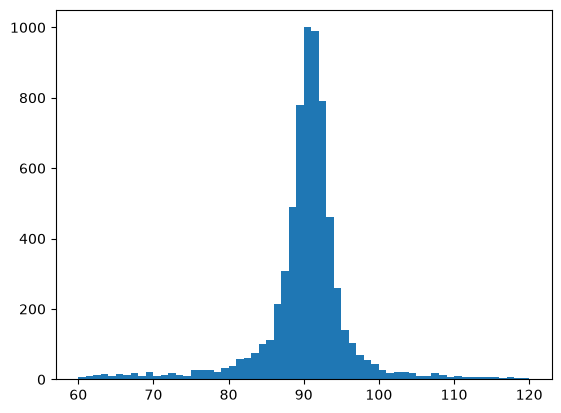

In [12]:
plt.hist(m_mumu, bins=60, range=(60, 120))

(array([10., 20., 16.,  9.,  8.,  7.,  9.,  9.,  9.,  9.,  9.,  7.,  3.,
         8.,  5.,  6.,  9.,  6.,  7., 13.,  3., 10.,  5.,  6.,  7.,  9.,
         3., 10.,  8.,  1.,  7.,  7.,  6.,  4.,  5.,  4.,  5.,  4.,  1.,
         7.,  1.,  1.,  3.,  2.,  2.,  2.,  1.,  3.,  1.,  0.,  1.,  0.,
         0.,  1.,  0.,  3.,  1.,  2.,  2.,  1.]),
 array([ 60.,  61.,  62.,  63.,  64.,  65.,  66.,  67.,  68.,  69.,  70.,
         71.,  72.,  73.,  74.,  75.,  76.,  77.,  78.,  79.,  80.,  81.,
         82.,  83.,  84.,  85.,  86.,  87.,  88.,  89.,  90.,  91.,  92.,
         93.,  94.,  95.,  96.,  97.,  98.,  99., 100., 101., 102., 103.,
        104., 105., 106., 107., 108., 109., 110., 111., 112., 113., 114.,
        115., 116., 117., 118., 119., 120.]),
 <BarContainer object of 60 artists>)

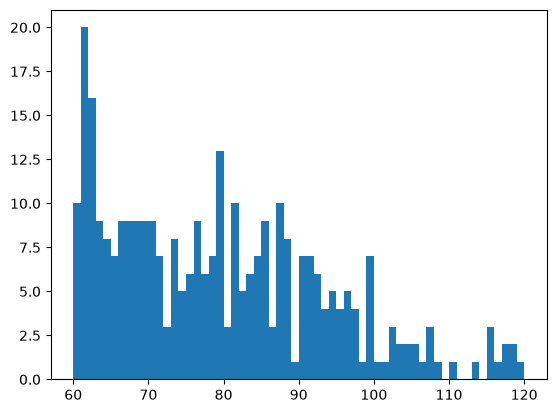

In [13]:
plt.hist(pt_mumu, bins=60, range=(60, 120))

In [14]:
file_60_120 = uproot.open("/afs/cern.ch/work/f/frresend/MG5_aMC_v3_5_17/test_dy/Events/dy_60_120/tag_1_delphes_events.root")
file_120_200 = uproot.open("/afs/cern.ch/work/f/frresend/MG5_aMC_v3_5_17/test_dy/Events/dy_120_200/tag_1_delphes_events.root")
file_200_500 = uproot.open("/afs/cern.ch/work/f/frresend/MG5_aMC_v3_5_17/test_dy/Events/dy_200_500/tag_1_delphes_events.root")
file_500_1000 = uproot.open("/afs/cern.ch/work/f/frresend/MG5_aMC_v3_5_17/test_dy/Events/dy_500_1000/tag_1_delphes_events.root")
file_1000_2000 = uproot.open("/afs/cern.ch/work/f/frresend/MG5_aMC_v3_5_17/test_dy/Events/dy_1000_2000/tag_1_delphes_events.root")
file_2000plus = uproot.open("/afs/cern.ch/work/f/frresend/MG5_aMC_v3_5_17/test_dy/Events/dy_2000plus/tag_1_delphes_events.root")

In [15]:
#60-120
delphes_events_60_120 = file_60_120['Delphes;1']
#print(delphes_events.keys())
muon_events_60_120 = delphes_events_60_120['Muon']
array_muon_events_60_120 = muon_events_60_120.array()
#120-200
delphes_events_120_200 = file_120_200['Delphes;1']
#print(delphes_events.keys())
muon_events_120_200 = delphes_events_120_200['Muon']
array_muon_events_120_200 = muon_events_120_200.array()
#200-500
delphes_events_200_500 = file_200_500['Delphes;1']
#print(delphes_events.keys())
muon_events_200_500 = delphes_events_200_500['Muon']
array_muon_events_200_500 = muon_events_200_500.array()
#500-1000
delphes_events_500_1000 = file_500_1000['Delphes;1']
#print(delphes_events.keys())
muon_events_500_1000 = delphes_events_500_1000['Muon']
array_muon_events_500_1000 = muon_events_500_1000.array()
#1000-2000
delphes_events_1000_2000 = file_1000_2000['Delphes;1']
#print(delphes_events.keys())
muon_events_1000_2000 = delphes_events_1000_2000['Muon']
array_muon_events_1000_2000 = muon_events_1000_2000.array()
#2000 plus
delphes_events_2000plus = file_2000plus['Delphes;1']
#print(delphes_events.keys())
muon_events_2000plus = delphes_events_2000plus['Muon']
array_muon_events_2000plus = muon_events_2000plus.array()

In [19]:
array_of_slices = [muon_events_60_120, muon_events_120_200, muon_events_200_500, muon_events_500_1000, muon_events_1000_2000, muon_events_2000plus]

In [25]:
cross_sections = [643.989, 6.996499999999999, 1.22594,  0.0572, 0.0039815, 0.000133562]
edges = np.geomspace(60, 3000, 61)   # 61 edges -> 60 log-spaced bins, defined once before the loop

total_counts = np.zeros(len(edges)-1)
for a, i in enumerate(array_of_slices):
    muon_eta = i['Muon.Eta']
    muon_phi = i['Muon.Phi']
    muon_charge = i['Muon.Charge']
    muon_pt = i['Muon.PT']
    print(muon_eta)
    #print(muon_events.keys())
    #print(muon_events['Muon_Size'])
    muon_events_eta_array = muon_eta.array()
    muon_events_pt_array = muon_pt.array()
    muon_events_charge_array = muon_charge.array()
    muon_events_phi_array = muon_phi.array()
    muons = i.arrays(["Muon.PT", "Muon.Eta", "Muon.Phi", "Muon.Charge"])
    mask = (ak.num(muon_events_pt_array) == 2) & (ak.sum(muon_events_charge_array, axis=1) == 0)
    muons_sel = muons[mask]

    muons_sel["Muon.PT"]   # pt of the selected events
    sel_pt = muons_sel["Muon.PT"]
    sel_eta = muons_sel["Muon.Eta"]
    sel_charge = muons_sel["Muon.Charge"]
    sel_phi = muons_sel["Muon.Phi"]
    E1, px1, py1, pz1 = to_cartesian(sel_pt[:, 0], sel_phi[:, 0],  sel_eta[:, 0],  sel_charge[:, 0] ) 
    E2, px2, py2, pz2 = to_cartesian(sel_pt[:, 1], sel_phi[:, 1],  sel_eta[:, 1],  sel_charge[:, 1] )
    E_tot = E1+E2
    px_tot = px1+px2
    py_tot = py1+py2
    pz_tot = pz1+pz2
    m_mumu = np.sqrt(E_tot**2-px_tot**2-py_tot**2-pz_tot**2)
    pt_mumu = np.sqrt(px_tot**2+py_tot**2) 
    w = cross_sections[a]/10000
    weights = np.full(len(m_mumu), w)
    edges = np.geomspace(60, 3000, 61)   # 61 edges -> 60 log-spaced bins, defined once before the loop
    m_mumu = np.array(m_mumu)
    # inside the loop:
    counts, _ = np.histogram(m_mumu, bins=edges, range=(60, 3000), weights = weights)
    total_counts += counts
    print(muon_events_eta_array, muon_events_pt_array, muon_events_charge_array, muon_events_phi_array)

<TBranchElement 'Muon.Eta' at 0x7f5354d3c050>
[[0.0158, 2.08], [], [1.11], [...], ..., [1.68, 1.23], [-0.759], [1.17, -1.64]] [[29.5, 28.6], [], [49.7], [51.1, ...], ..., [49.6, 41.4], [43.4], [39.8, 13.5]] [[-1, 1], [], [-1], [1, -1], [1, -1], ..., [1, -1], [1, -1], [1], [1, -1]] [[0.493, -2.57], [], [1.61], [...], ..., [-2.81, 0.817], [0.488], [1.39, 2.51]]
<TBranchElement 'Muon.Eta' at 0x7f5354916f00>
[[-1.66], [0.14], [-1.29, -0.334], ..., [...], [-1.2, -0.672], [-2.16, -0.938]] [[87.6], [60.7], [58.6, 57.3], ..., [71, 58.6], [59.5, 59.1], [58.1, 50.1]] [[-1], [1], [-1, 1], [-1, 1], [...], ..., [-1, 1], [1, -1], [-1, 1], [-1, 1]] [[3.02], [0.558], [2.36, -1.15], ..., [...], [-0.872, 2.31], [0.393, -2.16]]
<TBranchElement 'Muon.Eta' at 0x7f53542e9b50>
[[-2.12, 1.39], [0.662], [-1.95], ..., [...], [-0.35, -1.59], [0.509, 2.14]] [[81.5, 70.3], [81.4], [68], [...], ..., [56.9, 47.9], [119, 91.3], [103, 89.3]] [[-1, 1], [-1], [-1], [1, -1], [1], ..., [1, -1], [-1, 1], [1, -1], [1, -1]] 

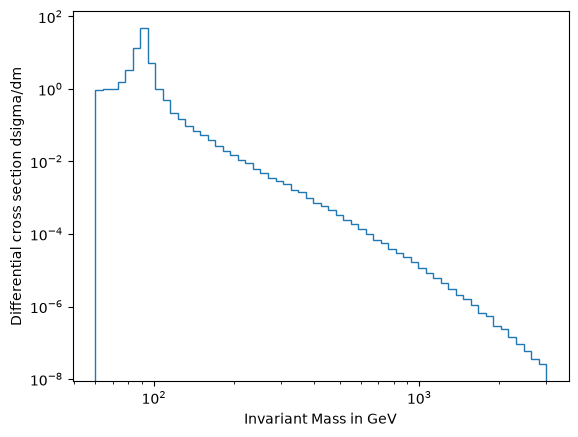

In [ ]:

bin_widths = np.diff(edges)
norm_tot_counts = total_counts/bin_widths
plt.yscale("log")
plt.xlabel("Invariant Mass in GeV")
plt.xscale('log')
plt.ylabel('Differential cross section dsigma/dm [pb/GeV]')
plt.stairs(norm_tot_counts, edges)